# PIA – Teoría de la Computación y Análisis de Algoritmos
## PMSP: generador de instancias, algoritmos y análisis experimental (hasta el orden experimental)
Equipo Neumann. Algoritmos: **Graham (List Scheduling)**, con el pseudocódigo del reporte (versión con estados y dependencias), y **LPT**.

Contenido: 1) generador de instancias, 2) implementación de ambos algoritmos, 3) Tabla 2 (30 ejecuciones por algoritmo), 4) gráficas, 5) ajuste de curva, 6) orden experimental.

## 1. Generador de instancias del PMSP
Una instancia es $I=\langle m, n, P\rangle$ con tiempos enteros positivos $p_j$. El parámetro opcional `p_dep` agrega dependencias (solo para el algoritmo de Graham del reporte); con `p_dep=0` la instancia es el PMSP estándar $P_m||C_{max}$ (tareas independientes).

In [1]:
import random, time, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def generar_instancia(n, m, p_min=1, p_max=100, p_dep=0.0, semilla=None):
    """Instancia del PMSP: n tareas, m máquinas idénticas, tiempos enteros en [p_min, p_max].
    p_dep: probabilidad de que la tarea j dependa de una tarea anterior (0 = PMSP independiente)."""
    rng = random.Random(semilla)
    P = [rng.randint(p_min, p_max) for _ in range(n)]
    deps = [[] for _ in range(n)]
    if p_dep > 0:
        for j in range(1, n):
            if rng.random() < p_dep:
                deps[j].append(rng.randrange(j))   # solo hacia atrás: sin ciclos
    return {"m": m, "n": n, "P": P, "deps": deps}

inst = generar_instancia(7, 3, 3, 8, semilla=1)
inst

{'m': 3,
 'n': 7,
 'P': [4, 7, 3, 5, 3, 6, 6],
 'deps': [[], [], [], [], [], [], []]}

## 2. Algoritmos

### Graham (List Scheduling) – pseudocódigo del reporte
Se implementa tal cual: inicialización de estados, ciclo principal de $n$ iteraciones y tres ciclos anidados de $n$ (asignar, buscar el menor tiempo de fin, desbloquear). Orden teórico del reporte: $O(n^2+nE)$.

In [2]:
def graham(P, m, deps=None):
    n = len(P)
    if deps is None: deps = [[] for _ in range(n)]
    DISP, BLOQ, PROG, TERM = 0, 1, 2, 3
    estado = [DISP if not deps[i] else BLOQ for i in range(n)]
    fin = [0] * n
    tiempo_actual, proc_libres, completadas = 0, m, 0
    while completadas < n:
        for i in range(n):                                   # ciclo A
            if proc_libres > 0 and estado[i] == DISP:
                estado[i] = PROG
                fin[i] = tiempo_actual + P[i]
                proc_libres -= 1
        t_min = -1
        for i in range(n):                                   # ciclo B
            if estado[i] == PROG and (t_min == -1 or fin[i] < fin[t_min]):
                t_min = i
        tiempo_actual = fin[t_min]
        estado[t_min] = TERM
        completadas += 1
        proc_libres += 1
        for i in range(n):                                   # ciclo C
            if estado[i] == BLOQ and all(estado[d] == TERM for d in deps[i]):
                estado[i] = DISP
    return tiempo_actual   # makespan

### LPT
Ordena las tareas de mayor a menor y asigna cada una a la máquina con menor carga acumulada. Orden teórico del reporte: $O(n\log n + nm)$.

In [3]:
def lpt(P, m):
    T = sorted(P, reverse=True)                  # O(n log n)
    carga = [0] * m
    asignacion = [[] for _ in range(m)]
    for t in T:                                  # n tareas
        menor = 0
        for j in range(1, m):                    # m-1 comparaciones
            if carga[j] < carga[menor]:
                menor = j
        asignacion[menor].append(t)
        carga[menor] += t
    return asignacion, max(carga)

Verificación con la instancia de ejemplo del reporte, $m=3$, $P=(8,7,6,5,4,3,3)$, donde $C^*_{max}=12$:

In [4]:
P_ej = [8, 7, 6, 5, 4, 3, 3]
print("LPT:", lpt(P_ej, 3))
print("Graham (orden de llegada):", graham(P_ej, 3))
print("Cota inferior:", max(math.ceil(sum(P_ej)/3), max(P_ej)))

LPT: ([[8, 3, 3], [7, 4], [6, 5]], 14)
Graham (orden de llegada): 14
Cota inferior: 12


## 3. Medición de tiempos
Cada tiempo es el promedio por llamada, repitiendo la ejecución hasta acumular al menos 50 ms (así se reduce el ruido en tamaños pequeños). Se usa `time.perf_counter`. Todas las instancias son PMSP estándar (sin dependencias, $E=0$) con $m=5$ máquinas y $p_j\in[1,100]$.

In [5]:
def medir(f, *args, minimo=0.05):
    reps, t0 = 0, time.perf_counter()
    while True:
        r = f(*args); reps += 1
        dt = time.perf_counter() - t0
        if dt >= minimo: break
    return dt / reps, r

M_MAQ = 5
def tabla(algoritmo, tamanos, reps_por_tamano=3):
    filas, k = [], 1
    for n in tamanos:
        for r in range(reps_por_tamano):
            inst = generar_instancia(n, M_MAQ, semilla=1000 * n + r)
            if algoritmo == "Graham":
                t, mk = medir(graham, inst["P"], M_MAQ, inst["deps"])
            else:
                t, res = medir(lpt, inst["P"], M_MAQ); mk = res[1]
            filas.append({"#": k, "Instancia": f"I{n}-{r+1}", "Tamaño (n)": n, "Tiempo (s)": t, "Makespan": mk})
            k += 1
    return pd.DataFrame(filas)

## 4. Tabla 2 – Graham (30 ejecuciones)
10 tamaños ($n=100,200,\dots,1000$) × 3 instancias.

In [6]:
T_graham = tabla("Graham", range(100, 1001, 100))
T_graham.style.format({"Tiempo (s)": "{:.6f}"}).hide(axis="index")

#,Instancia,Tamaño (n),Tiempo (s),Makespan
1,I100-1,100,0.001696,1168
2,I100-2,100,0.001561,964
3,I100-3,100,0.001535,1033
4,I200-1,200,0.005900,2158
5,I200-2,200,0.005926,1843
6,I200-3,200,0.005955,2183
7,I300-1,300,0.013913,3210
8,I300-2,300,0.013467,3090
9,I300-3,300,0.013553,3098
10,I400-1,400,0.024424,4064


## 5. Tabla 2 – LPT (30 ejecuciones)
LPT es mucho más rápido, por lo que se usan tamaños mayores: 10 tamaños ($n=20\,000,40\,000,\dots,200\,000$) × 3 instancias.

In [18]:
T_lpt = tabla("LPT", range(20000, 200001, 20000))
T_lpt.style.format({"Tiempo (s)": "{:.6f}"}).hide(axis="index")

#,Instancia,Tamaño (n),Tiempo (s),Makespan
1,I20000-1,20000,0.012746,200054
2,I20000-2,20000,0.017057,202798
3,I20000-3,20000,0.012652,202470
4,I40000-1,40000,0.025575,405151
5,I40000-2,40000,0.025472,404200
6,I40000-3,40000,0.025238,405222
7,I60000-1,60000,0.037898,602631
8,I60000-2,60000,0.038617,604661
9,I60000-3,60000,0.038214,605966
10,I80000-1,80000,0.050837,807026


## 6. Gráficas de tiempo de ejecución vs. tamaño de instancia
Para cada tamaño se grafica la **mediana** de sus 3 ejecuciones.

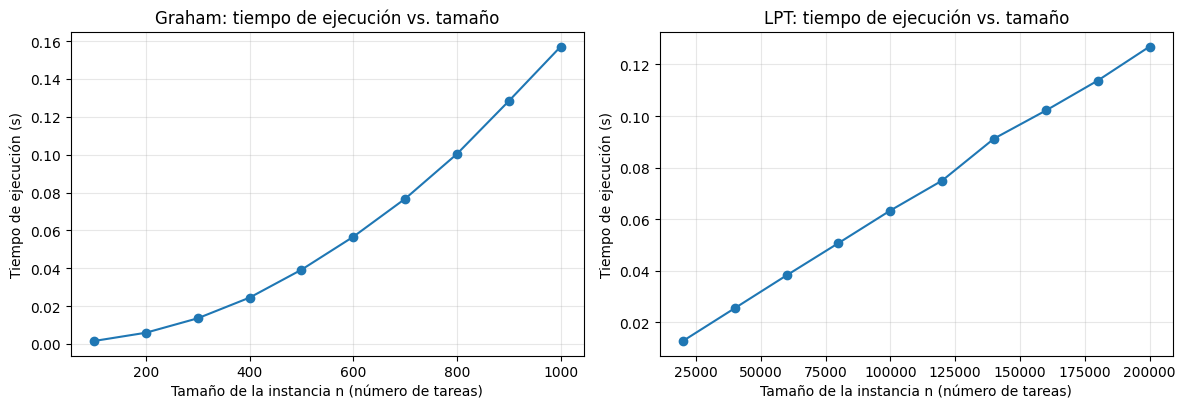

In [19]:
def resumen(T):
    return T.groupby("Tamaño (n)")["Tiempo (s)"].median().reset_index()

R_g, R_l = resumen(T_graham), resumen(T_lpt)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, R, nombre in [(ax[0], R_g, "Graham"), (ax[1], R_l, "LPT")]:
    a.plot(R["Tamaño (n)"], R["Tiempo (s)"], "o-")
    a.set_title(f"{nombre}: tiempo de ejecución vs. tamaño")
    a.set_xlabel("Tamaño de la instancia n (número de tareas)"); a.set_ylabel("Tiempo de ejecución (s)")
    a.grid(alpha=.3)
plt.tight_layout(); plt.savefig("graficas_tiempos.png", dpi=200); plt.show()

## 7. Ajuste de curva
Dos pasos por algoritmo:
1. **Exponente empírico:** regresión lineal en escala log-log, $\log t = \log c + b\log n$.
2. **Comparación de modelos:** ajuste por mínimos cuadrados (`curve_fit`) de $t=a\,f(n)+c$ con $f\in\{n,\;n\log n,\;n^2,\;n^3\}$ y comparación por $R^2$ y error cuadrático medio relativo (RMSE entre el tiempo máximo). El orden experimental es el del modelo con mejor ajuste.

In [20]:
modelos = {
    "n":       lambda n, a, c: a * n + c,
    "n log n": lambda n, a, c: a * n * np.log2(n) + c,
    "n^2":     lambda n, a, c: a * n**2 + c,
    "n^3":     lambda n, a, c: a * n**3 + c,
}

def ajustar(R, nombre):
    n = R["Tamaño (n)"].values.astype(float); t = R["Tiempo (s)"].values
    b, logc = np.polyfit(np.log(n), np.log(t), 1)
    filas, params = [], {}
    for nom, f in modelos.items():
        popt, _ = curve_fit(f, n, t)
        pred = f(n, *popt)
        ss_res, ss_tot = np.sum((t - pred)**2), np.sum((t - t.mean())**2)
        filas.append({"Modelo": f"O({nom})", "a": popt[0], "c": popt[1],
                      "R²": 1 - ss_res/ss_tot, "RMSE / t_max": np.sqrt(np.mean((t-pred)**2)) / t.max()})
        params[nom] = popt
    df = pd.DataFrame(filas).sort_values("R²", ascending=False).reset_index(drop=True)
    print(f"{nombre}: exponente log-log b = {b:.3f}")
    return df, params, b

aj_g, par_g, b_g = ajustar(R_g, "Graham")
display(aj_g.style.format({"a": "{:.3e}", "c": "{:.3e}", "R²": "{:.5f}", "RMSE / t_max": "{:.4f}"}).hide(axis="index"))
aj_l, par_l, b_l = ajustar(R_l, "LPT")
display(aj_l.style.format({"a": "{:.3e}", "c": "{:.3e}", "R²": "{:.5f}", "RMSE / t_max": "{:.4f}"}).hide(axis="index"))

Graham: exponente log-log b = 2.017


Modelo,a,c,R²,RMSE / t_max
O(n^2),1.579e-07,-4.114e-04,0.99994,0.0024
O(n^3),1.550e-10,1.350e-02,0.97460,0.0519
O(n log n),1.682e-05,-2.583e-02,0.96404,0.0618
O(n),1.737e-04,-3.512e-02,0.94901,0.0736


LPT: exponente log-log b = 0.999


Modelo,a,c,R²,RMSE / t_max
O(n),6.359e-07,4.073e-06,0.99944,0.0068
O(n log n),3.523e-08,4.218e-03,0.99892,0.0095
O(n^2),2.744e-12,2.770e-02,0.94824,0.0655
O(n^3),1.298e-17,3.854e-02,0.85920,0.1080


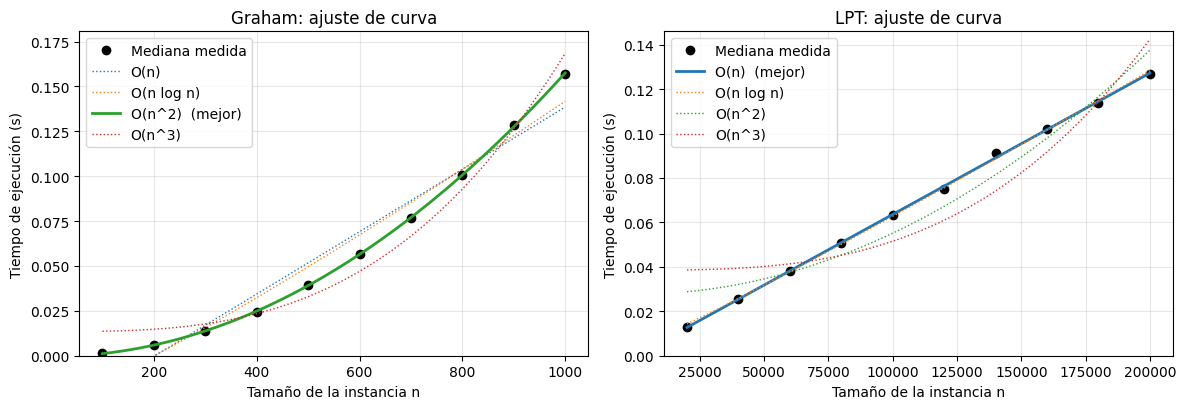

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, R, par, aj, nombre in [(ax[0], R_g, par_g, aj_g, "Graham"), (ax[1], R_l, par_l, aj_l, "LPT")]:
    n = R["Tamaño (n)"].values.astype(float); nn = np.linspace(n.min(), n.max(), 200)
    a.plot(n, R["Tiempo (s)"], "ko", label="Mediana medida")
    mejor = aj.loc[0, "Modelo"][2:-1]
    for nom, f in modelos.items():
        a.plot(nn, f(nn, *par[nom]), "-" if nom == mejor else ":", lw=2 if nom == mejor else 1, label=f"O({nom})" + ("  (mejor)" if nom == mejor else ""))
    a.set_title(f"{nombre}: ajuste de curva"); a.set_xlabel("Tamaño de la instancia n"); a.set_ylabel("Tiempo de ejecución (s)")
    a.set_ylim(0, R["Tiempo (s)"].max() * 1.15); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig("ajuste_curvas.png", dpi=200); plt.show()

## 8. Orden obtenido (experimental)

In [22]:
def orden(aj):
    return aj.loc[0, "Modelo"]
print(f"Graham: mejor ajuste {orden(aj_g)}  (R² = {aj_g.loc[0,'R²']:.5f}); exponente log-log = {b_g:.2f}")
print(f"LPT:    mejor ajuste {orden(aj_l)}  (R² = {aj_l.loc[0,'R²']:.5f}); exponente log-log = {b_l:.2f}")

Graham: mejor ajuste O(n^2)  (R² = 0.99994); exponente log-log = 2.02
LPT:    mejor ajuste O(n)  (R² = 0.99944); exponente log-log = 1.00


## Extra: calidad de las soluciones (mismas instancias, $n=100\dots1000$)
Comparación del makespan de Graham (orden de llegada) y de LPT contra la cota inferior $LB=\max(\lceil\sum p_j/m\rceil,\;\max p_j)$.

In [23]:
filas = []
for n in range(100, 1001, 100):
    for r in range(3):
        inst = generar_instancia(n, M_MAQ, semilla=1000 * n + r)
        P = inst["P"]; LB = max(math.ceil(sum(P)/M_MAQ), max(P))
        filas.append({"n": n, "LB": LB, "Graham": graham(P, M_MAQ), "LPT": lpt(P, M_MAQ)[1]})
Q = pd.DataFrame(filas)
Q["Graham/LB"] = Q.Graham / Q.LB; Q["LPT/LB"] = Q.LPT / Q.LB
Q.groupby("n")[["Graham/LB", "LPT/LB"]].mean().round(4)

,Graham/LB,LPT/LB
n,,
100,1.0280,1.0003
200,1.0138,1.0000
300,1.0117,1.0000
400,1.0099,1.0000
500,1.0075,1.0000
600,1.0081,1.0000
700,1.0018,1.0000
800,1.0053,1.0000
900,1.0034,1.0000
